# BS49903 · DS/AI for Biology
## Week 5 Practice Notebook — Dimensionality Reduction, Classification and Clustering

Covers Week 5-1 (PCA, UMAP) and Week 5-2 (k-nearest neighbors, k-means).

In [3]:
import warnings; warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler

np.set_printoptions(precision=3, suppress=True)

---
# Part 1 · The data

569 biopsies, 30 features measured from cell nuclei, and one label per biopsy.

In [4]:
data = load_breast_cancer()
X, y = data.data, data.target          # (569, 30), 0 = malignant, 1 = benign

print("shape:", X.shape)
print("malignant:", (y == 0).sum(), "  benign:", (y == 1).sum())

df = pd.DataFrame(X, columns=data.feature_names)
df.head()

shape: (569, 30)
malignant: 212   benign: 357


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


---
# Part 2 · Standardization

### 2.1 Features live on wildly different scales

In [5]:
df[["mean area", "mean radius", "mean fractal dimension"]].agg(["mean", "std"]).round(3)

,mean area,mean radius,mean fractal dimension
mean,654.889,14.127,0.063
std,351.914,3.524,0.007


"mean area" is in the hundreds, "mean fractal dimension" is around 0.06. Every method in
this notebook measures Euclidean distance, so without rescaling, area alone would decide
everything.

### 2.2 Subtract the mean, divide by the SD

$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

In [6]:
X_scaled = StandardScaler().fit_transform(X)

print("mean of the first 3 features:", X_scaled.mean(axis=0)[:3])
print("sd   of the first 3 features:", X_scaled.std(axis=0)[:3])

mean of the first 3 features: [-0. -0. -0.]
sd   of the first 3 features: [1. 1. 1.]


Now every feature has mean 0 and SD 1, so each one contributes comparably to a distance.

---
# Part 3 · Principal component analysis (PCA)

### 3.1 Same data, new axes

PCA rotates the coordinate system so the first axis carries as much variance as possible,
the second the most of what is left, and so on.

In [7]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
Z = pca.fit_transform(X_scaled)        # (569, 2): the PC scores

print("Z shape:", Z.shape)
print("explained variance ratio:", pca.explained_variance_ratio_)

Z shape: (569, 2)
explained variance ratio: [0.443 0.19 ]


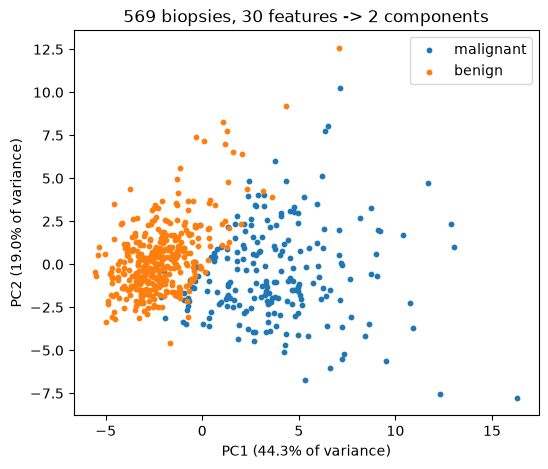

In [8]:
plt.figure(figsize=(6, 5))
plt.scatter(Z[y == 0, 0], Z[y == 0, 1], s=10, label="malignant")
plt.scatter(Z[y == 1, 0], Z[y == 1, 1], s=10, label="benign")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} of variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} of variance)")
plt.title("569 biopsies, 30 features -> 2 components")
plt.legend(); plt.show()

The colors are only for us to look at: PCA never saw the labels. 30 numbers per biopsy
were replaced by 2, and the two groups already sit in different places.

### 3.2 What is inside the fitted model

`components_` holds the new axes, one row per component. The scores are just the
standardized data projected onto them: $Z = X W^{\top}$.

In [9]:
W = pca.components_                       # (2, 30)

print("components_ shape:", W.shape)
print("length of each component:", np.linalg.norm(W, axis=1))   # unit vectors

print("Z == X_scaled @ W.T ?", np.allclose(Z, X_scaled @ W.T))

components_ shape: (2, 30)
length of each component: [1. 1.]
Z == X_scaled @ W.T ? True


Each component is a weighted sum of all 30 original features. The largest weights tell
you what PC1 actually measures:

In [10]:
order = np.argsort(np.abs(W[0]))[::-1][:5]
for j in order:
    print(f"{data.feature_names[j]:>24}  {W[0][j]:+.3f}")

     mean concave points  +0.261
          mean concavity  +0.258
    worst concave points  +0.251
        mean compactness  +0.239
         worst perimeter  +0.237


PC1 is mostly "how big and how irregular is the nucleus" — one summary axis built out of
many correlated measurements.

### 3.3 Explained variance: how many components do we need?

PC1 + PC2 together: 63.2%
components needed for 95% of the variance: 10


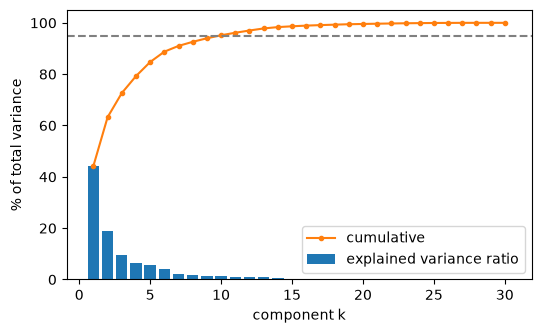

In [11]:
pca_all = PCA().fit(X_scaled)
ratio = pca_all.explained_variance_ratio_
cum = np.cumsum(ratio)

k95 = int(np.argmax(cum >= 0.95)) + 1
print("PC1 + PC2 together:", f"{cum[1]:.1%}")
print("components needed for 95% of the variance:", k95)

ks = np.arange(1, 31)
plt.figure(figsize=(6, 3.5))
plt.bar(ks, ratio * 100, label="explained variance ratio")
plt.plot(ks, cum * 100, "o-", color="C1", ms=3, label="cumulative")
plt.axhline(95, ls="--", color="gray")
plt.xlabel("component k"); plt.ylabel("% of total variance")
plt.legend(); plt.show()

PCA is **linear** (a rotation), **deterministic** (same answer every time) and fast.

---
# Part 4 · UMAP

### 4.1 Same data, no axes

UMAP builds a neighbor graph in the full 30-dimensional space, then lays the points out on
a plane so that connected points stay close and unconnected points are pushed apart.

embedding shape: (569, 2)


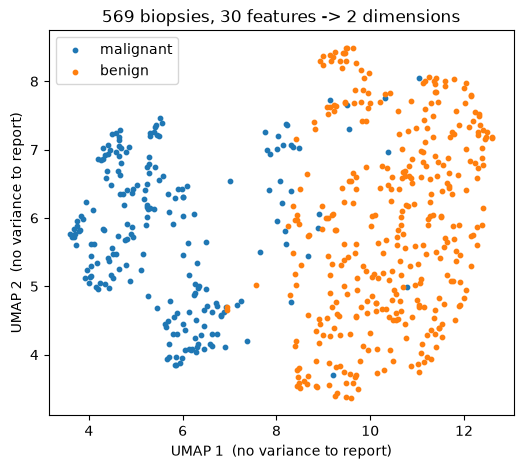

In [12]:
import umap                      # pip install umap-learn

reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="euclidean", random_state=0)
E = reducer.fit_transform(X_scaled)        # (569, 2)

print("embedding shape:", E.shape)

plt.figure(figsize=(6, 5))
plt.scatter(E[y == 0, 0], E[y == 0, 1], s=10, label="malignant")
plt.scatter(E[y == 1, 0], E[y == 1, 1], s=10, label="benign")
plt.xlabel("UMAP 1  (no variance to report)")
plt.ylabel("UMAP 2  (no variance to report)")
plt.title("569 biopsies, 30 features -> 2 dimensions")
plt.legend(); plt.show()

There is no `components_` and no `explained_variance_ratio_`: the embedding is not the data
times a matrix, so the axes carry no meaning and cannot be interpreted.

### 4.2 The two parameters

- `n_neighbors`: how far each point looks. Small = fine local detail, large = overall shape.
- `min_dist`: how tightly points may clump together in the plane.

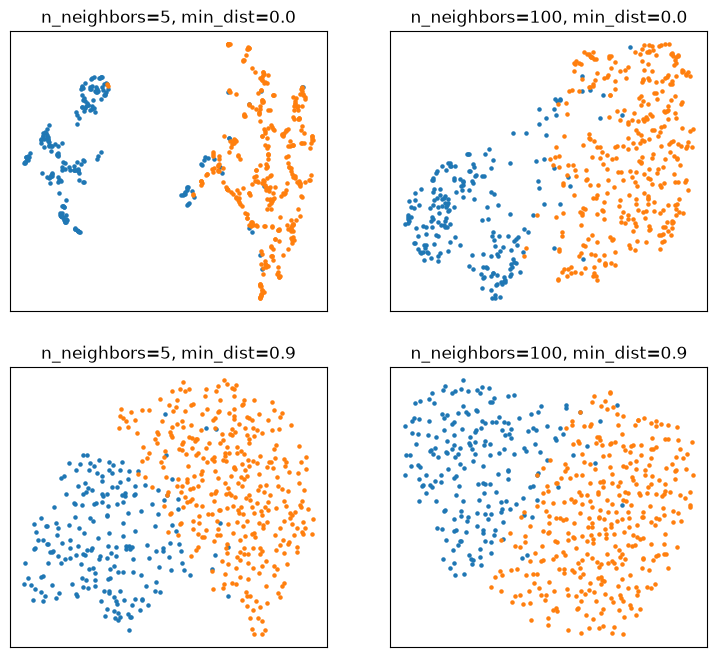

In [13]:
settings = [(5, 0.0), (100, 0.0), (5, 0.9), (100, 0.9)]

fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for ax, (n, d) in zip(axes.ravel(), settings):
    e = umap.UMAP(n_neighbors=n, min_dist=d, random_state=0).fit_transform(X_scaled)
    ax.scatter(e[y == 0, 0], e[y == 0, 1], s=5)
    ax.scatter(e[y == 1, 0], e[y == 1, 1], s=5)
    ax.set_title(f"n_neighbors={n}, min_dist={d}")
    ax.set_xticks([]); ax.set_yticks([])
plt.show()

Change the parameters and the picture changes. UMAP is also **stochastic**: drop
`random_state` and you get a different layout every run. Never read a cluster size or a
distance between clusters off a UMAP plot.

---
# Part 5 · k-nearest neighbors

### 5.1 Classify

The test set must behave like samples we have never seen, so the scaler is fitted on the training set only.

In [14]:
from sklearn.model_selection import train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

scaler = StandardScaler().fit(X_tr)                  # fit on the training set only
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

print(X_tr_s.shape, X_te_s.shape)

(398, 30) (171, 30)


In [15]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=15)
knn.fit(X_tr_s, y_tr)                               # just stores the data

print("predictions:", knn.predict(X_te_s[:5]))
print("true labels:", y_te[:5])
print("test accuracy:", round(knn.score(X_te_s, y_te), 3))

predictions: [0 1 0 1 0]
true labels: [0 0 0 1 0]
test accuracy: 0.942


No weights, no loss function, no gradient descent — all the work happens at prediction time.

### 5.2 What does k do?

In [16]:
for k in [1, 5, 15, 50, 150]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_tr_s, y_tr)
    print(f"k = {k:3d}   train {m.score(X_tr_s, y_tr):.3f}   test {m.score(X_te_s, y_te):.3f}")

k =   1   train 1.000   test 0.947
k =   5   train 0.980   test 0.947
k =  15   train 0.970   test 0.942
k =  50   train 0.955   test 0.947
k = 150   train 0.910   test 0.889


k = 1 is perfect on the training set because every training point is its own nearest
neighbor — it **overfits**, and that number says nothing about new samples. A very large k
smooths the boundary until it **underfits**.

### 5.3 Choosing k with cross-validation

The test set stays untouched, so k is chosen inside the training set: cut it into 5 folds,
hold one out at a time, average the 5 scores.

best k by cross-validation: 9


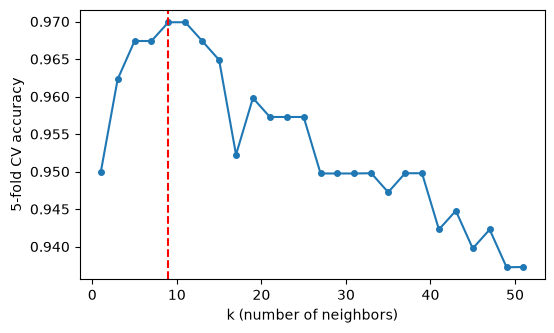

In [17]:
from sklearn.model_selection import cross_val_score

ks = np.arange(1, 52, 2)
cv = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_tr_s, y_tr, cv=5).mean() for k in ks]

k_best = int(ks[int(np.argmax(cv))])
print("best k by cross-validation:", k_best)

plt.figure(figsize=(6, 3.5))
plt.plot(ks, cv, "o-", ms=4)
plt.axvline(k_best, color="red", ls="--")
plt.xlabel("k (number of neighbors)"); plt.ylabel("5-fold CV accuracy"); plt.show()

In [18]:
# the test set is used exactly once, at the very end, with the chosen k
final = KNeighborsClassifier(n_neighbors=k_best).fit(X_tr_s, y_tr)
print("test accuracy with k =", k_best, ":", round(final.score(X_te_s, y_te), 3))

test accuracy with k = 9 : 0.947


---
# Part 6 · k-means

### 6.1 Cluster

No labels go in. `k` is the number of clusters, and we choose it ourselves.

In [38]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X_scaled)

print("cluster ids:", km.labels_[:10])
print("centroid shape:", km.cluster_centers_.shape)   # (2, 30)
print("inertia:", round(km.inertia_))

cluster ids: [1 1 1 1 1 1 1 1 1 1]
centroid shape: (2, 30)
inertia: 11596


Only *afterwards* do we compare the clusters with the diagnosis:

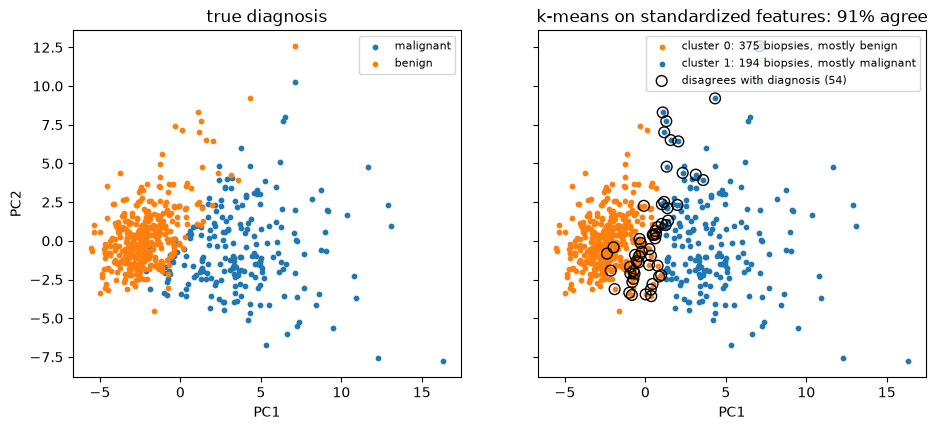

In [39]:
def compare_with_diagnosis(labels, title):
    """Plot the clusters next to the diagnosis on the PCA axes from Part 3."""
    # cluster ids are arbitrary: name each cluster after the diagnosis most of its members have
    majority = {c: np.bincount(y[labels == c]).argmax() for c in np.unique(labels)}
    guess = np.array([majority[c] for c in labels])
    wrong = guess != y

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
    for name, v in [("malignant", 0), ("benign", 1)]:
        axes[0].scatter(Z[y == v, 0], Z[y == v, 1], s=10, color=f"C{v}", label=name)
    for c, v in majority.items():
        m = labels == c
        axes[1].scatter(Z[m, 0], Z[m, 1], s=10, color=f"C{v}",
                        label=f"cluster {c}: {m.sum()} biopsies, mostly {data.target_names[v]}")
    axes[1].scatter(Z[wrong, 0], Z[wrong, 1], s=60, facecolors="none", edgecolors="k",
                    label=f"disagrees with diagnosis ({wrong.sum()})")
    axes[0].set_title("true diagnosis")
    axes[1].set_title(f"{title}: {(~wrong).mean():.0%} agree")
    for ax in axes:
        ax.set_xlabel("PC1"); ax.legend(fontsize=8)
    axes[0].set_ylabel("PC2")
    plt.show()

compare_with_diagnosis(km.labels_, "k-means on standardized features")

The clusters were found without the labels, and they still line up with the diagnosis.

### 6.2 How many clusters?

**Elbow**: look for the bend where extra clusters stop paying off.
**Silhouette**: how much closer each sample is to its own cluster than to the nearest other
one, from -1 to 1.

k = 1   inertia    17070   silhouette nan
k = 2   inertia    11596   silhouette 0.343
k = 3   inertia    10062   silhouette 0.314
k = 4   inertia     9330   silhouette 0.159
k = 5   inertia     8556   silhouette 0.163
k = 6   inertia     7967   silhouette 0.162
k = 7   inertia     7536   silhouette 0.153


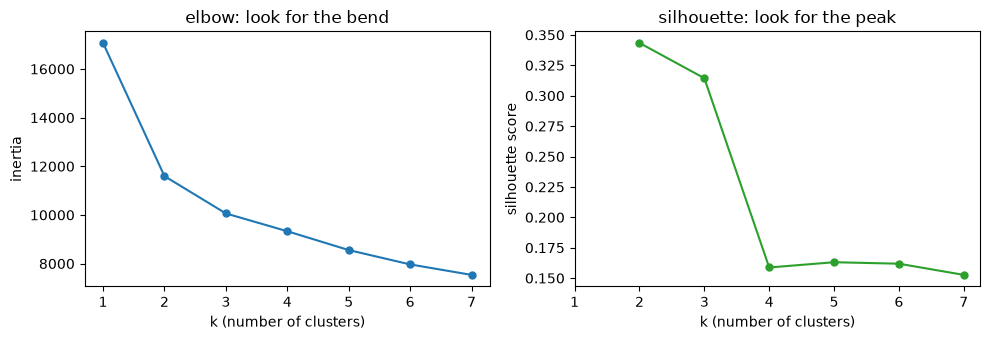

In [40]:
from sklearn.metrics import silhouette_score

ks = list(range(1, 8))
inertia, sil = [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_scaled)
    inertia.append(m.inertia_)
    sil.append(silhouette_score(X_scaled, m.labels_) if k > 1 else np.nan)   # undefined for one cluster
    print(f"k = {k}   inertia {m.inertia_:8.0f}   silhouette {sil[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(ks, inertia, "o-", ms=5)
axes[0].set_title("elbow: look for the bend")
axes[0].set_ylabel("inertia")
axes[1].plot(ks[1:], sil[1:], "o-", ms=5, color="C2")
axes[1].set_title("silhouette: look for the peak")
axes[1].set_ylabel("silhouette score")
for ax in axes:
    ax.set_xlabel("k (number of clusters)"); ax.set_xticks(ks)
plt.tight_layout(); plt.show()

Inertia can only fall as k grows, so it cannot pick k on its own. The silhouette peaks at
k = 2.

### 6.3 Standardization matters here too

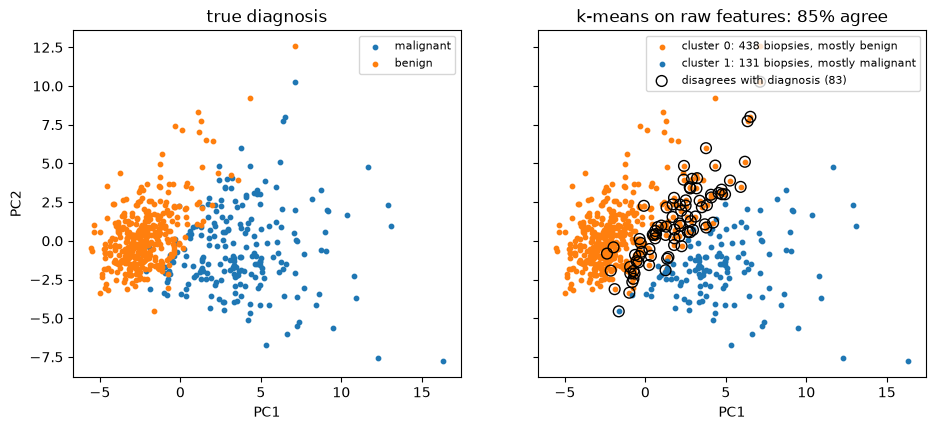

In [41]:
km_raw = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X)     # raw features
compare_with_diagnosis(km_raw.labels_, "k-means on raw features")

| k-means on | Agree with diagnosis | Biopsies that disagree |
|---|---|---|
| Standardized features (6.1) | 91% | 54 |
| Raw features (6.3) | 85% | 83 |

On the raw features the distance is dominated by "mean area" and "worst area" (SD in the
hundreds), and the clusters match the diagnosis much less well.

k-means also *assumes* round clusters of similar spread, and every point is forced into a
cluster — so noise drags the centroids around.